# Segmentación de clientes de comercio electrónico mediante técnicas de clustering

## 1. Introducción

En el sector del comercio electrónico, comprender el comportamiento de compra de los clientes es fundamental para diseñar estrategias de marketing, fidelización y retención. Sin embargo, las empresas suelen manejar grandes volúmenes de transacciones que dificultan identificar patrones de comportamiento mediante análisis tradicionales.

Este proyecto propone utilizar técnicas de aprendizaje automático no supervisado para identificar segmentos de clientes con características de compra similares, utilizando el conjunto de datos Online Retail de UCI Machine Learning Repository.

Se implementarán y compararán dos algoritmos de clustering: K-Means y Gaussian Mixture Models (GMM). Se realizarán procesos de limpieza de datos, ingeniería y selección de características, optimización de hiperparámetros, validación cruzada repetida y comparación estadística de los modelos.

### Objetivo general
Identificar y analizar grupos de clientes con comportamientos de compra similares mediante técnicas de clustering, determinando cuál de los algoritmos estudiados proporciona una segmentación más adecuada según métricas de validación interna y criterios estadísticos.

### Objetivos específicos
- Analizar la calidad, estructura y distribución de los datos transaccionales.
- Construir variables representativas del comportamiento de compra mediante el enfoque RFM.
- Implementar pipelines de preprocesamiento y clustering.
- Optimizar los hiperparámetros de K-Means y GMM.
- Comparar estadísticamente el desempeño de ambas técnicas.
- Visualizar los segmentos mediante t-SNE e interpretar sus características comerciales.

### Pregunta de investigación
¿Cuál de los algoritmos, K-Means o Gaussian Mixture Models, permite identificar segmentos de clientes más consistentes y diferenciados a partir de su comportamiento de compra?

### Consideración metodológica
El dataset no contiene etiquetas verdaderas de segmentos; por tanto, métricas supervisadas como accuracy no son pertinentes. Los segmentos descubiertos requieren interpretación comercial y no representan categorías previamente verificadas.

### 2. Descripción de los datos

El conjunto de datos Online Retail registra las transacciones de un comercio electrónico sin tienda física establecido en el Reino Unido. Según UCI, su cobertura es del 1 de diciembre de 2010 al 9 de diciembre de 2011, con 541.909 filas y 8 columnas en el archivo original. La empresa comercializa principalmente regalos; una parte de sus compradores son mayoristas.

**Unidad de análisis original:** línea de factura o transacción, no cliente. Un cliente puede aparecer en muchas filas e incluso una factura puede tener varios productos. Antes del clustering se agruparán las transacciones a nivel de CustomerID.

**Aspectos a investigar:** identificadores faltantes, duplicados, cancelaciones, cantidades no positivas, precios no positivos, distribución temporal, concentración geográfica, importes extremos y número de clientes identificables. Se deben calcular los resultados sobre los datos leídos y no asumirlos únicamente por la ficha del repositorio.

## 4. Preprocesamiento y construcción de características

In [17]:
import pandas as pd
import numpy as np

# Trabajar siempre desde el dataset original
df_tx = df.copy()

# Normalización de tipos
df_tx["CustomerID"] = pd.to_numeric(
    df_tx["CustomerID"], errors="coerce"
)

df_tx["InvoiceNo"] = (
    df_tx["InvoiceNo"].astype("string").str.strip()
)

df_tx["InvoiceDate"] = pd.to_datetime(
    df_tx["InvoiceDate"], errors="coerce"
)

df_tx["Quantity"] = pd.to_numeric(
    df_tx["Quantity"], errors="coerce"
)

df_tx["UnitPrice"] = pd.to_numeric(
    df_tx["UnitPrice"], errors="coerce"
)

# Conservar transacciones identificables con importe válido
condiciones = (
    df_tx["CustomerID"].notna()
    & df_tx["InvoiceNo"].notna()
    & df_tx["InvoiceDate"].notna()
    & (df_tx["UnitPrice"] > 0)
    & (df_tx["Quantity"] != 0)
    & df_tx["Quantity"].notna()
)

df_tx = df_tx.loc[condiciones].copy()

# Calcular importes positivos y negativos
df_tx["Importe"] = (
    df_tx["Quantity"] * df_tx["UnitPrice"]
)

# Identificar cancelaciones
df_tx["EsCancelacion"] = (
    df_tx["InvoiceNo"]
    .str.upper()
    .str.startswith("C", na=False)
)

# Compras positivas para variables de actividad
df_compras = df_tx[
    (df_tx["Quantity"] > 0)
    & (~df_tx["EsCancelacion"])
].copy()

print("Transacciones utilizables:", len(df_tx))
print("Líneas de compras positivas:", len(df_compras))
print("Líneas de importe negativo:", (df_tx["Importe"] < 0).sum())
print("Clientes con compras:", df_compras["CustomerID"].nunique())

Transacciones utilizables: 406789
Líneas de compras positivas: 397884
Líneas de importe negativo: 8905
Clientes con compras: 4338


In [20]:
# Fecha de referencia
fecha_referencia = (
    df_tx["InvoiceDate"].max()
    + pd.Timedelta(days=1)
)

# Características basadas en compras positivas
rfm = df_compras.groupby("CustomerID").agg(
    LastPurchase=("InvoiceDate", "max"),
    Frequency=("InvoiceNo", "nunique"),
    GrossMonetary=("Importe", "sum"),
    ProductDiversity=("StockCode", "nunique")
)

# Importe neto: compras menos devoluciones
neto = df_tx.groupby("CustomerID")["Importe"].sum()

rfm["Monetary"] = neto.round(2)

# Recencia respecto a última compra positiva
rfm["Recency"] = (
    fecha_referencia - rfm["LastPurchase"]
).dt.days

# Auditoría antes de excluir clientes
print("Clientes antes del filtro:", len(rfm))
print("Clientes con gasto neto <= 0:",
      (rfm["Monetary"] <= 0).sum())

print("\nCliente 12346:")
display(rfm.loc[[12346]])

# Conservar clientes con gasto neto positivo
rfm = rfm[rfm["Monetary"] > 0].copy()

# Ticket promedio neto por factura positiva
rfm["AvgTicket"] = (
    rfm["Monetary"] / rfm["Frequency"]
)

rfm = rfm.reset_index()

# Ordenar columnas
rfm = rfm[
    [
        "CustomerID",
        "Recency",
        "Frequency",
        "Monetary",
        "AvgTicket",
        "ProductDiversity"
    ]
]

print("\nDataset RFM corregido:")
print("Dimensiones:", rfm.shape)

display(rfm.head())
display(rfm.describe())

Clientes antes del filtro: 4338
Clientes con gasto neto <= 0: 21

Cliente 12346:


,LastPurchase,Frequency,GrossMonetary,ProductDiversity,Monetary,Recency
CustomerID,,,,,,
"12,346.00",2011-01-18 10:01:00,1,"77,183.60",1,0.00,326



Dataset RFM corregido:
Dimensiones: (4317, 6)


,CustomerID,Recency,Frequency,Monetary,AvgTicket,ProductDiversity
0,"12,347.00",2,7,"4,310.00",615.71,103
1,"12,348.00",75,4,"1,797.24",449.31,22
2,"12,349.00",19,1,"1,757.55","1,757.55",73
3,"12,350.00",310,1,334.40,334.40,17
4,"12,352.00",36,8,"1,545.41",193.18,59


,CustomerID,Recency,Frequency,Monetary,AvgTicket,ProductDiversity
count,"4,317.00","4,317.00","4,317.00","4,317.00","4,317.00","4,317.00"
mean,"15,300.12",92.25,4.29,"1,925.71",367.96,61.74
std,"1,720.24",99.84,7.71,"8,267.65",399.87,85.49
min,"12,347.00",1.00,1.00,2.90,1.45,1.00
25%,"13,815.00",18.00,1.00,302.70,175.20,16.00
50%,"15,299.00",51.00,2.00,658.26,284.55,36.00
75%,"16,778.00",141.00,5.00,"1,627.13",423.33,78.00
max,"18,287.00",374.00,209.00,"279,489.02","7,178.63","1,787.00"


In [19]:
# Comparar importes netos conservando y eliminando duplicados
neto_original = (
    df_tx.groupby("CustomerID")["Importe"].sum()
)

neto_sin_duplicados = (
    df_tx.drop_duplicates()
    .groupby("CustomerID")["Importe"]
    .sum()
)

comparacion = pd.DataFrame({
    "ConDuplicados": neto_original,
    "SinDuplicados": neto_sin_duplicados
})

comparacion["Diferencia"] = (
    comparacion["ConDuplicados"]
    - comparacion["SinDuplicados"]
)

print(
    "Clientes con diferencia monetaria:",
    (comparacion["Diferencia"].abs() > 0.001).sum()
)

print(
    "Diferencia neta total:",
    round(comparacion["Diferencia"].sum(), 2)
)

print("\nMayores diferencias absolutas:")

display(
    comparacion.reindex(
        comparacion["Diferencia"].abs()
        .sort_values(ascending=False)
        .index
    ).head(10)
)

Clientes con diferencia monetaria: 958
Diferencia neta total: 21546.39

Mayores diferencias absolutas:


,ConDuplicados,SinDuplicados,Diferencia
CustomerID,,,
"16,029.00","50,992.61","53,168.69","-2,176.08"
"12,748.00","29,072.10","28,405.56",666.54
"17,841.00","40,340.78","39,869.05",471.73
"14,607.00","11,341.10","10,981.10",360.00
"16,762.00","1,501.38","1,207.24",294.14
"14,769.00","10,641.60","10,383.83",257.77
"14,102.00","1,314.73","1,060.33",254.40
"13,316.00","5,815.49","5,570.69",244.80
"15,856.00","16,173.67","15,929.74",243.93


### Resultados del preprocesamiento y tratamiento de transacciones

La reconstrucción del conjunto de características permitió obtener inicialmente 4.322 clientes con gasto neto positivo, tras excluir 16 clientes cuyo saldo monetario era nulo o negativo. Esta modificación corrigió situaciones en las que las compras posteriormente devueltas producían una sobreestimación del valor económico del cliente.

El análisis de sensibilidad de los duplicados identificó diferencias monetarias en 958 clientes y una variación neta agregada de £21.546,39. Sin embargo, dado que no es posible determinar con certeza si todas las coincidencias corresponden a errores de registro, se decidió conservarlas inicialmente y evaluar posteriormente su influencia sobre la estabilidad de la segmentación.

Las características obtenidas presentan distribuciones heterogéneas y valores extremos, especialmente en las variables monetarias y de frecuencia. En consecuencia, se considera necesario evaluar transformaciones estadísticas, escalamiento y selección de características antes de aplicar los algoritmos de clustering.

## 5. Análisis de características y selección de variables

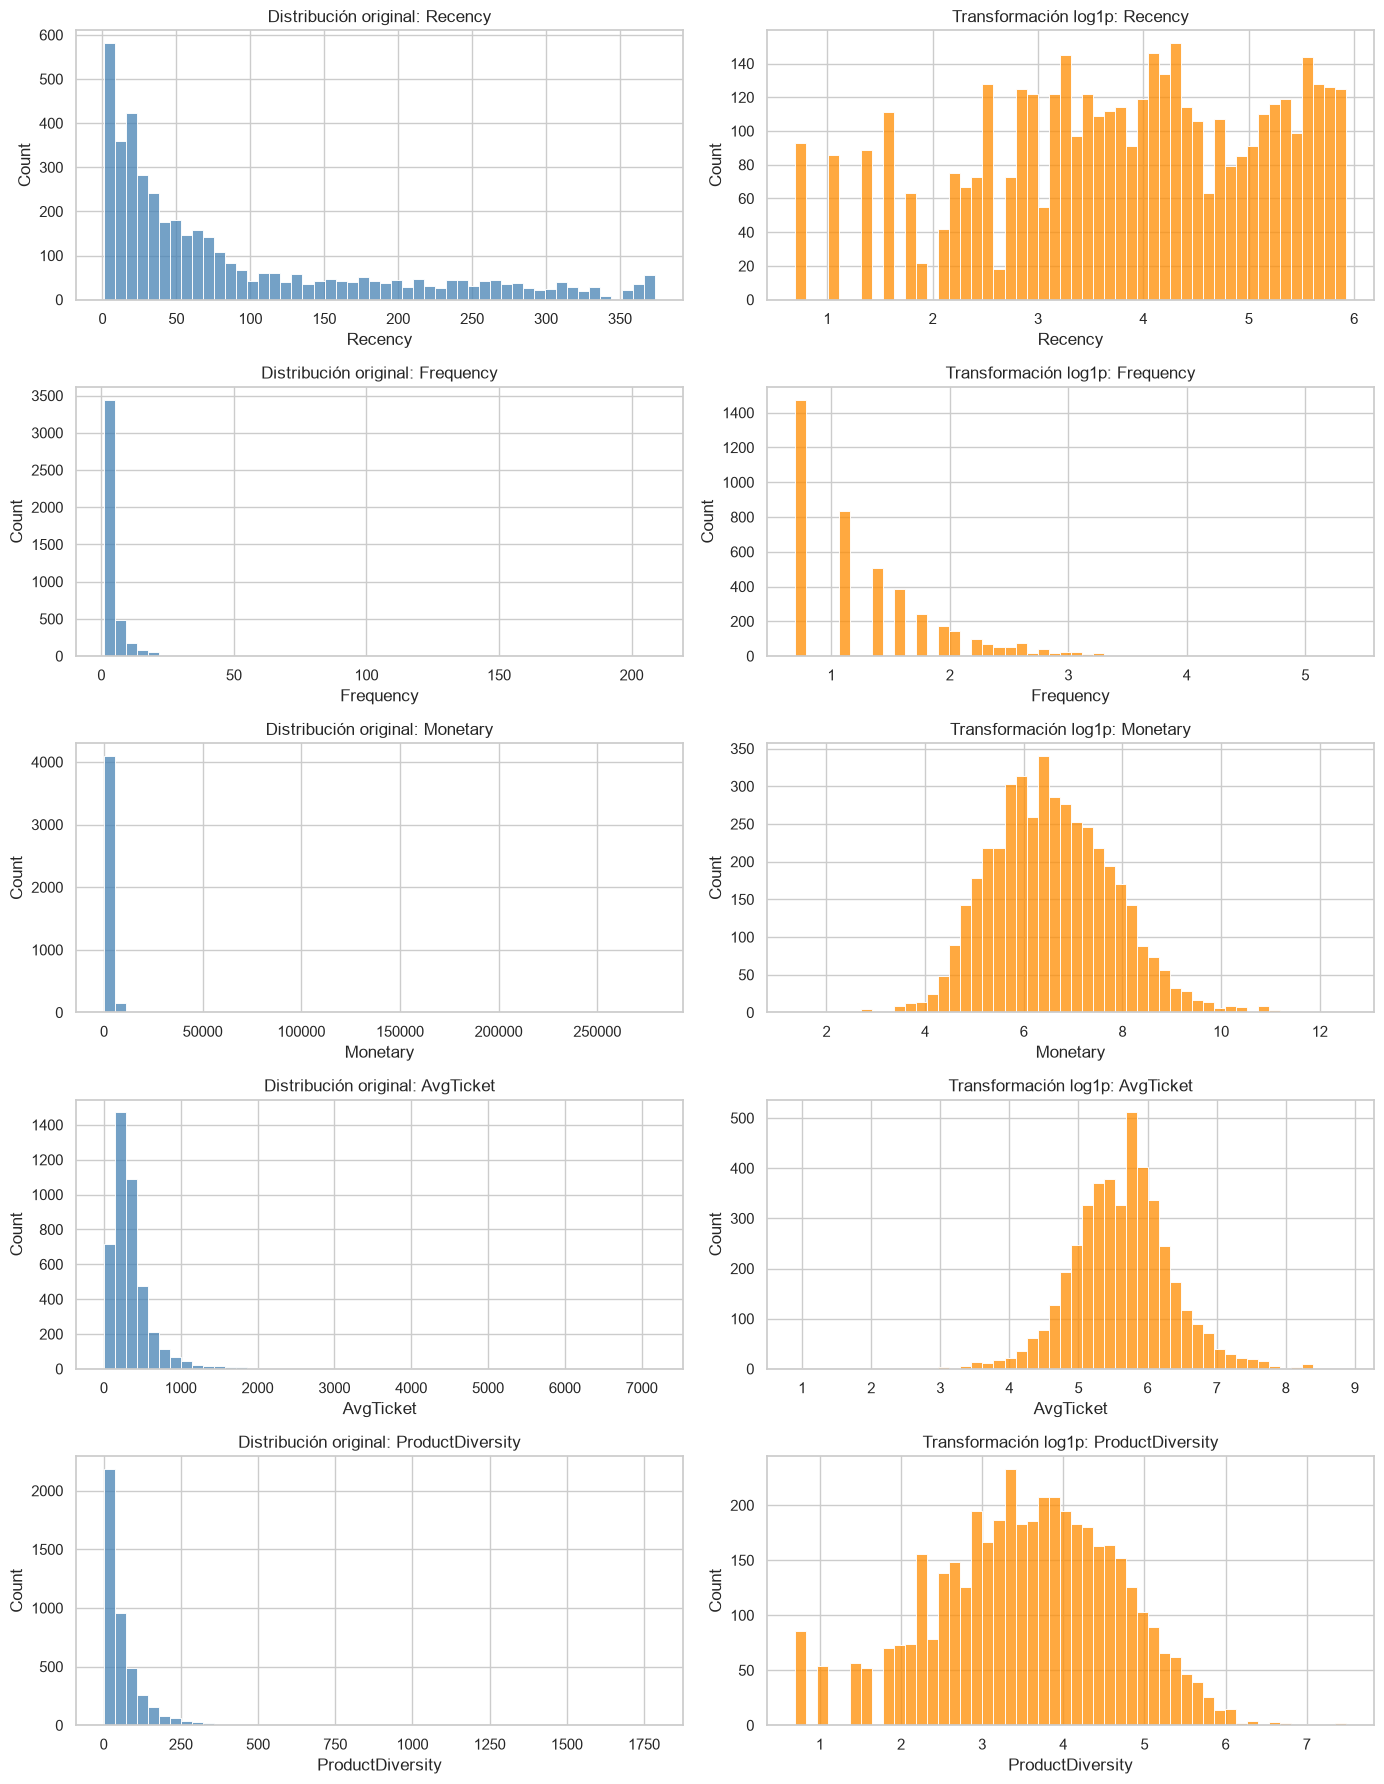

,Original,Log1p
Recency,1.25,-0.38
Frequency,12.05,1.20
Monetary,21.59,0.37
AvgTicket,6.50,-0.00
ProductDiversity,6.92,-0.24


In [21]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

variables = [
    "Recency",
    "Frequency",
    "Monetary",
    "AvgTicket",
    "ProductDiversity"
]

fig, axes = plt.subplots(
    len(variables), 2,
    figsize=(14, 18)
)

for i, variable in enumerate(variables):

    # Distribución original
    sns.histplot(
        rfm[variable],
        bins=50,
        ax=axes[i, 0],
        color="steelblue"
    )

    axes[i, 0].set_title(
        f"Distribución original: {variable}"
    )

    # Distribución transformada
    sns.histplot(
        np.log1p(rfm[variable]),
        bins=50,
        ax=axes[i, 1],
        color="darkorange"
    )

    axes[i, 1].set_title(
        f"Transformación log1p: {variable}"
    )

plt.tight_layout()
plt.show()

# Medir asimetría
asimetria = pd.DataFrame({
    "Original": rfm[variables].skew(),
    "Log1p": np.log1p(rfm[variables]).skew()
})

display(asimetria.round(3))

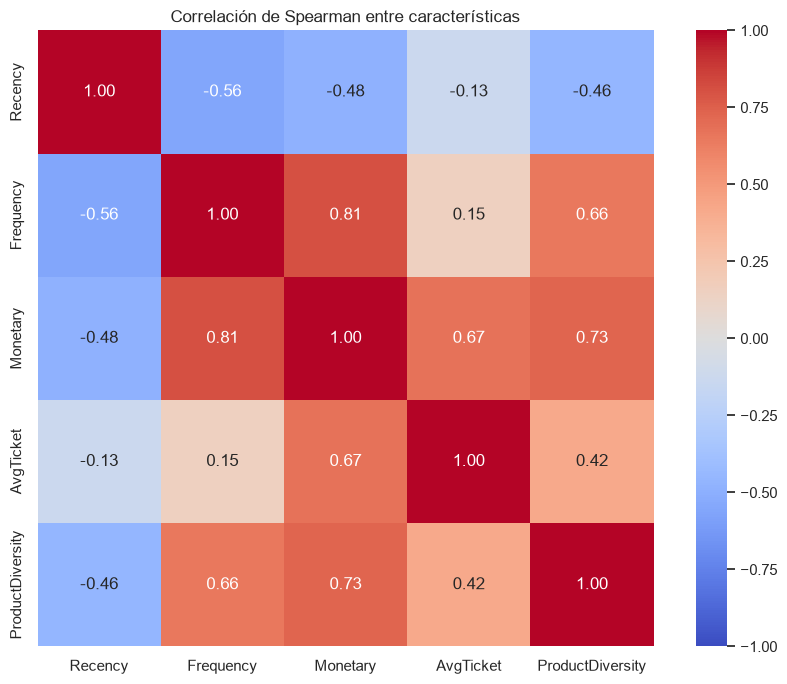

Pares con correlación absoluta >= 0.85:


,Variable 1,Variable 2,Correlacion,AbsCorrelacion


In [22]:
# Correlación de Spearman
corr = rfm[variables].corr(method="spearman")

plt.figure(figsize=(9, 7))

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1,
    square=True
)

plt.title(
    "Correlación de Spearman entre características"
)

plt.tight_layout()
plt.show()

# Identificar pares altamente correlacionados
umbral = 0.85

mascara = np.triu(
    np.ones(corr.shape, dtype=bool),
    k=1
)

pares = (
    corr.where(mascara)
    .stack()
    .reset_index()
)

pares.columns = [
    "Variable 1",
    "Variable 2",
    "Correlacion"
]

pares["AbsCorrelacion"] = (
    pares["Correlacion"].abs()
)

pares_altos = pares[
    pares["AbsCorrelacion"] >= umbral
].sort_values(
    "AbsCorrelacion",
    ascending=False
)

print("Pares con correlación absoluta >= 0.85:")
display(pares_altos)

### Conclusiones del análisis de características

El análisis de las variables RFM evidenció distribuciones marcadamente asimétricas, especialmente en las características monetarias y de frecuencia. La transformación logarítmica log1p redujo considerablemente dicha asimetría, destacándose la variable Monetary, cuyo coeficiente pasó de 21,59 a 0,37.

El análisis de correlación de Spearman identificó una asociación positiva elevada entre Frequency y Monetary (0,81), así como una relación negativa moderada entre Recency y Frequency (−0,56). Estos resultados indican que existen características parcialmente redundantes que podrían influir en la ponderación implícita de las distancias utilizadas por los algoritmos.

Por tanto, se decidió incorporar transformaciones logarítmicas, estandarización y selección de características por correlación dentro del pipeline de aprendizaje automático. Se evaluarán distintos umbrales de selección mediante validación cruzada, con el objetivo de determinar si la reducción de variables contribuye a obtener segmentos de clientes más diferenciados y estables.

## 6. Pipeline de preprocesamiento y selección de características

In [23]:
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split

# Copia del dataset de clientes
rfm_modelo = rfm.copy()

# Redondear importes monetarios para evitar residuos numéricos
rfm_modelo["Monetary"] = (
    rfm_modelo["Monetary"].round(2)
)

# Excluir importes netos no positivos
rfm_modelo = rfm_modelo[
    rfm_modelo["Monetary"] > 0
].copy()

# Actualizar ticket promedio
rfm_modelo["AvgTicket"] = (
    rfm_modelo["Monetary"]
    / rfm_modelo["Frequency"]
)

# Características candidatas
# Monetary precede a Frequency como prioridad de conservación
features = [
    "Recency",
    "Monetary",
    "Frequency",
    "ProductDiversity"
]

X = rfm_modelo[features].copy()

assert X.notna().all().all()
assert np.isfinite(X.to_numpy()).all()
assert (X >= 0).all().all()

# Reservar un conjunto independiente
X_desarrollo, X_reserva = train_test_split(
    X,
    test_size=0.20,
    random_state=42,
    shuffle=True
)

print("Dataset completo:", X.shape)
print("Conjunto de desarrollo:", X_desarrollo.shape)
print("Conjunto de reserva:", X_reserva.shape)

display(X_desarrollo.head())

Dataset completo: (4317, 4)
Conjunto de desarrollo: (3453, 4)
Conjunto de reserva: (864, 4)


,Recency,Monetary,Frequency,ProductDiversity
279,70,869.67,2,32
3435,131,496.38,1,13
3523,8,"3,286.91",6,42
1864,2,"1,025.44",2,66
2028,60,"1,419.54",4,74
